### Датасет - miteshpadiya/data-cleancsv

Предобработка будет сделана для 2 случаев - для дальнейшего обучения модели и для визуализации:

* `model_data`
* `dashboard_data`

Целевой признак в `model_data` - уровень озона `('Ozone')`

In [1]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.impute import KNNImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split

In [2]:
# создаем папки для будущих данных
os.makedirs('./data/', exist_ok=True)
os.makedirs('./train/', exist_ok=True)
os.makedirs('./test/', exist_ok=True)
os.makedirs('./dashboard/', exist_ok=True)

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("miteshpadiya/data-cleancsv", output_dir='./data/')
print("Path to dataset files:", path)

c:\Users\angel\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: ./data/


In [4]:
df = pd.read_csv('./data/data_clean.csv')

In [5]:
print(os.listdir('./data/'))

['.complete', 'data_clean.csv']


Диагностика оригинального датафрейма.

In [6]:
df.head(10)

,Unnamed: 0,Ozone,Solar.R,Wind,Temp C,Month,Day,Year,Temp,Weather
0,1,41.0,190.0,7.4,67,5,1,2010,67,S
1,2,36.0,118.0,8.0,72,5,2,2010,72,C
2,3,12.0,149.0,12.6,74,5,3,2010,74,PS
3,4,18.0,313.0,11.5,62,5,4,2010,62,S
4,5,NaN,NaN,14.3,56,5,5,2010,56,S
5,6,28.0,NaN,14.9,66,5,6,2010,66,C
6,7,23.0,299.0,8.6,65,5,7,2010,65,PS
7,8,19.0,99.0,13.8,59,5,8,2010,59,C
8,9,8.0,19.0,20.1,61,5,9,2010,61,PS
9,10,NaN,194.0,8.6,69,5,10,2010,69,S


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 158 entries, 0 to 157
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  158 non-null    int64  
 1   Ozone       120 non-null    float64
 2   Solar.R     151 non-null    float64
 3   Wind        158 non-null    float64
 4   Temp C      158 non-null    str    
 5   Month       158 non-null    str    
 6   Day         158 non-null    int64  
 7   Year        158 non-null    int64  
 8   Temp        158 non-null    int64  
 9   Weather     155 non-null    str    
dtypes: float64(3), int64(4), str(3)
memory usage: 12.5 KB


In [8]:
df.describe()

,Unnamed: 0,Ozone,Solar.R,Wind,Day,Year,Temp
count,158.000000,120.000000,151.000000,158.000000,158.000000,158.0,158.000000
mean,79.500000,41.583333,185.403974,9.957595,16.006329,2010.0,77.727848
std,45.754781,32.620709,88.723103,3.511261,8.997166,0.0,9.377877
min,1.000000,1.000000,7.000000,1.700000,1.000000,2010.0,56.000000
25%,40.250000,18.000000,119.000000,7.400000,8.000000,2010.0,72.000000
50%,79.500000,30.500000,197.000000,9.700000,16.000000,2010.0,78.500000
75%,118.750000,61.500000,257.000000,11.875000,24.000000,2010.0,84.000000
max,158.000000,168.000000,334.000000,20.700000,31.000000,2010.0,97.000000


In [9]:
df.shape

(158, 10)

In [10]:
print(df.isnull().sum())

Unnamed: 0     0
Ozone         38
Solar.R        7
Wind           0
Temp C         0
Month          0
Day            0
Year           0
Temp           0
Weather        3
dtype: int64


<Axes: >

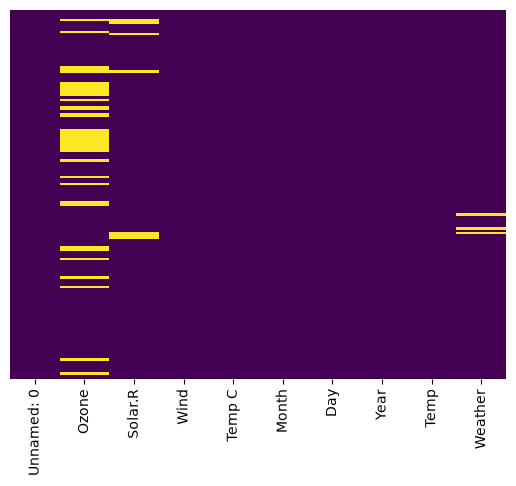

In [11]:
sns.heatmap(df.isnull(), yticklabels=False, cbar=False, cmap='viridis')
# визуализируем пропущенные значения

In [12]:
# оставляем колонки, в которых количество уникальных значений > 1 ('Year')
df = df[[c for c in list(df) if len(df[c].unique()) > 1]] 

# удаляем колонку 'Unnamed: 0'
# удаляем колонку 'Temp C', она является String копией колонки 'Temp'
df = df.drop(columns=['Unnamed: 0', 'Temp C'])

# удаляем строки с пропусками в колонце 'Weather'
df = df.dropna(subset='Weather')

df.shape

(155, 7)

In [13]:
print(df.duplicated().sum())
df = df.drop_duplicates() # удаляем дубликаты
df.shape

1


(154, 7)

In [14]:
for col in list(df.select_dtypes(exclude=[np.number])):
    print(f'{col} : {df[col].unique()}', '\n')

# заменим 'May' на 5
df['Month'] = df['Month'].replace({'May': '5'})

print(df['Month'].unique())

Month : <StringArray>
['5', 'May', '6', '7', '8', '9']
Length: 6, dtype: str 

Weather : <StringArray>
['S', 'C', 'PS']
Length: 3, dtype: str 

<StringArray>
['5', '6', '7', '8', '9']
Length: 5, dtype: str


Для подготовки `model_data` необходимо выбрать целевой признак.

Выберем `'Ozone'` в качестве целевого признака в `model_data`.

Ограничение - 158 строк.

Такого количества строк будет недостаточно для устойчивой модели.

Но в данном конкретном примере это осознанны компромисс для демонстрации пайплайна подготовки данных к обучению.

## Обработка для `model_data`
### Количественные данные. Работа с пропусками.

Поскольку признак `'Ozone'` - целевой, заполнять пропуски в нем не будем, просто удалим строки с пропусками по данному признаку.

## Обработка для `model_data`
### Количественные данные. Работа с пропусками.

Поскольку признак `'Ozone'` - целевой, заполнять пропуски в нем не будем, просто удалим строки с пропусками по данному признаку.

In [15]:
model_data = df.copy()
model_data = model_data.dropna(subset=['Ozone'])

Удалим колонку 'Day', поскольку она не несет в себе важной информации для целефой переменной, для модели признак может послужить шумом.

In [16]:
model_data = model_data.drop(columns='Day')

In [17]:
num_col = list(model_data.select_dtypes(include=[np.number]))
cat_col = list(model_data.select_dtypes(exclude=[np.number]))
print(num_col, cat_col)

['Ozone', 'Solar.R', 'Wind', 'Temp'] ['Month', 'Weather']


In [18]:
# проверяем, есть ли среди количественных данных замаскированные под них категориальные
print(df[num_col].nunique())
# по каждому из признаков количество уникальных значений достаточно много,
# замаскированных под них категориальных признаков нет

Ozone       66
Solar.R    116
Wind        31
Temp        40
dtype: int64


Перед заполнением пропусков поделим данные на `train` и `test`, чтобы избежать утечки даныных.

In [21]:
X = model_data.drop(columns=['Ozone'])
y = model_data['Ozone']

train_X, test_X, train_y, test_y = train_test_split(
    X,
    y,
    test_size=0.2,
    shuffle=True,
    random_state=42)

In [22]:
num_cols = X.select_dtypes(include=[np.number]).columns
nan_num_cols = [c for c in num_cols if train_X[c].isnull().any()]

print(nan_num_cols)

['Solar.R']


Приведем числовые данные к единому масштабу с помощью `StandardScaler` из модуля `preprossesing` библиотеки `sklearn`

In [23]:
num_cols_to_scale = ['Solar.R', 'Wind', 'Temp']
scaler = StandardScaler()
train_X[num_cols_to_scale] = scaler.fit_transform(train_X[num_cols_to_scale])
test_X[num_cols_to_scale] = scaler.transform(test_X[num_cols_to_scale])

Для восстановления пропусков воcпользуемся `KNNImputer` из библиотеки `Sklearn`.

Для каждого пропуска в данных алгоритм находит `k` наиболее похожих строк, которые будут являться ближайшими соседями по известным признакам, расстояние вычисляется по формуле евклидова расстояния. У 5 соседей, где искомый признак известен, пропуск заполняется средним или взвешенным средним значением. При параметре `weights = distance` ближайшие соседи имеют больший вес на финальное значение.




In [24]:
train_num_imputed = train_X.copy()
test_num_imputed = test_X.copy()

imputer = KNNImputer(
    n_neighbors=5,
    weights='distance'
    )

col_for_knn = ['Solar.R', 'Wind', 'Temp'] # day и month не берем в качестве опорных данных

train_num_imputed[col_for_knn] = imputer.fit_transform(train_X[col_for_knn])
test_num_imputed[col_for_knn] = imputer.transform(test_X[col_for_knn])

print(train_num_imputed[col_for_knn].isnull().sum(), '\n'*2,'-'*45 ,'\n',sep='')

train_X[nan_num_cols] = train_num_imputed[nan_num_cols]
test_X[nan_num_cols] = test_num_imputed[nan_num_cols]

print(train_X.head(), '\n'*2,'-'*45 ,'\n',sep='')
print(test_X.head())



Solar.R    0
Wind       0
Temp       0
dtype: int64

---------------------------------------------

      Solar.R      Wind Month      Temp Weather
17  -1.160915  2.366045     5 -2.228953       C
104  0.973147  0.470103     8  0.497958       S
47   1.093530  2.998025     6 -0.592807       C
29   0.425952 -1.123588     5  0.170728       C
86  -1.128083 -0.326742     7  0.497958       C

---------------------------------------------

      Solar.R      Wind Month      Temp Weather
122  0.042915 -0.958723     8  1.806875       C
5   -0.255859  1.404335     5 -1.247265       C
69   0.962203 -1.123588     7  1.588722       C
67   1.005979 -1.288452     7  1.152416       C
12   1.159193 -0.161878     5 -1.247265       S


Проведем операцию `One-Hot-Encoding` для категориальных данных

In [25]:
# Создаем One-Hot-Encoder
encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False,
    drop=None
    )

encoded_train_X = encoder.fit_transform(train_X[cat_col])
encoded_test_X = encoder.transform(test_X[cat_col])

new_cols = encoder.get_feature_names_out(cat_col)

# Создаем датафрем из полученных данных
df_encoded_train_X = pd.DataFrame(encoded_train_X, columns=new_cols, index=train_X.index)
df_encoded_test_X = pd.DataFrame(encoded_test_X, columns=new_cols, index=test_X.index)

train_X = pd.concat([train_X.drop(columns=cat_col), df_encoded_train_X], axis=1)
test_X = pd.concat([test_X.drop(columns=cat_col), df_encoded_test_X], axis=1)

print(list(train_X.columns) == list(test_X.columns))   # True




True


Порверка совпадения размерности полученнных данных.

In [26]:
print(test_X.shape)
print(test_y.shape)
print(train_X.shape)
print(train_y.shape)

(24, 11)
(24,)
(92, 11)
(92,)


Сохранение данных

In [27]:
names = {
    'test_X' : test_X,
    'test_y' : test_y,
    'train_X' : train_X,
    'train_y' : train_y
    }

for name, obj in names.items():
    lil_path = name.split('_')[0]
    path = f'./{lil_path}/{name}.csv'
    if not os.path.exists(path):
        names[name].to_csv(path, index=False)
    


## Обработка для `dashboard_data`
Работа с пропусками.



In [28]:
df.head()

,Ozone,Solar.R,Wind,Month,Day,Temp,Weather
0,41.0,190.0,7.4,5,1,67,S
1,36.0,118.0,8.0,5,2,72,C
2,12.0,149.0,12.6,5,3,74,PS
3,18.0,313.0,11.5,5,4,62,S
4,NaN,NaN,14.3,5,5,56,S


In [29]:
path = './dashboard/dashboard_data.csv'
if not os.path.exists(path):
    df.to_csv(path, index=False)